In [120]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
from statsmodels.api import OLS
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from functools import partial
import statsmodels.api as sm

In [77]:
from sklearn.pipeline import Pipeline #step-by-step recipe
from sklearn.decomposition import PCA #It reduces the number of features by combining them into new ones (called principal components) that keep the most important information.
from sklearn.cross_decomposition import PLSRegression #Partial Least Squares Regression, selects variables explain variance
from ISLP.models import \
     (Stepwise,
      sklearn_selected,
      sklearn_selection_path)
from l0bnb import fit_path #does subset selection (finds the path)


In [78]:
df = pd.read_stata("dataset_merged.dta")

In [ ]:
# Transform advertisement types into binary columns
dummies = pd.get_dummies(df["ad_condition"], drop_first=True, dtype=int)
# Add those dummies to the dataframe and define as df2
df2 = pd.concat([df, dummies], axis=1)
# Rename binary columns for better readability
df2 = df2.rename(columns={
    1: "lostgirls_genre",
    2: "lostgirls_plain",
    3: "lostgirls_price",
    4: "stateline_genre",
    5: "stateline_plain",
    6: "stateline_price",
    "age_years": "age" 
})
# Group price ads across different genres
df2["price_ad"] = df2["lostgirls_price"] + df2["stateline_price"]
# Define the interaction term
df2["price_age"] = df2["price_ad"] * df2["age"]
# Group genre ads across different ad types; end result is stateline vs. lostgirls
df2["book_ad"] = df2["stateline_plain"] + df2["stateline_price"]
# Define a new column that takes lostgirls purchase information
df2["purchase"] = df2["purchased_203"]
# Insert the stateline purchase information into "purchase"
df2.loc[df2["book_ad"] == 1, "purchase"] = df2["purchased_303"]
# Define a new column that takes lostgirls search information
df2["search"] = df2["clicked_203"]
# Insert the stateline search information into "search"
df2.loc[df2["book_ad"] == 1, "search"] = df2["clicked_303"]
# Take observations that contains one of 2, 3, 5, 6 in the "ad_condition" column, and define as df3
df3 = df2[df2["ad_condition"].isin([2, 3, 5, 6])].copy()
# Define a list of relevant variables.
columns = [
    "purchase", "price_ad", "age", "book_ad", "price_age",
    "income1", "income2", "income3", "income4", "income5",
    "female", "black", "hispanic", "asian",
    "bachelor", "master", "some_college",
    "married", "divorced",
    "ebooks", "printbooks",
    "romance_rank", "mystery_rank",
    "fantasy_rank", "scifi_rank"
]

# Keep only relevant columns and remove missing observations
df4 = df3[columns].dropna().copy()

# Define a list of categorical variables
categorical = [
    "ebooks", "printbooks",
    "romance_rank", "mystery_rank",
    "fantasy_rank", "scifi_rank"
]

# Convert categorical variables into dummies
df4 = pd.get_dummies(
    df4,
    columns=categorical,
    drop_first=True,
    dtype=int
)

Brier: 0.06924501952799977
ROC AUC: 0.6012418177442168


In [138]:
design = MS(df4.columns.drop('purchase')).fit(df4)
Y = np.array(df4['purchase'])
X = design.transform(df4)
K = 5
kfold = skm.KFold(K,
                  random_state=0,
                  shuffle=True)

Ridge Regression

In [139]:
D  = design.fit_transform(df4).drop('intercept', axis=1); X = np.asarray(D)
Xs = (X - X.mean(0)) / X.std(0)
lambdas = 10**np.linspace(8, -2, 100) / Y.std()
soln_array = skl.ElasticNet.path(Xs, Y, l1_ratio=0., alphas=lambdas)[1]

pipe = Pipeline([('scaler', StandardScaler()), ('ridge', skl.ElasticNet(l1_ratio=0))])
grid = skm.GridSearchCV(pipe, {'ridge__alpha': lambdas}, cv=kfold,
                        scoring='neg_mean_squared_error').fit(X, Y)

ridgeCV = skl.ElasticNetCV(alphas=lambdas, l1_ratio=0, cv=kfold)
pipeCV  = Pipeline([('scaler', StandardScaler()), ('ridge', ridgeCV)]).fit(X, Y)
tuned = pipeCV.named_steps['ridge']; tuned.alpha_, tuned.mse_path_.mean(1).min(), tuned.coef_
optimal_lambda_ridge = grid.best_params_['ridge__alpha']

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:701: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:701: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.695e+02, tolerance: 5.390e-02
  model = cd_fast.enet_coordinate_descent_gram(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:701: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularizati

In [140]:
soln_path = pd.DataFrame(soln_array.T,
                         columns=D.columns,
                         index=-np.log(lambdas))
soln_path.index.name = 'negative log(lambda)'
soln_path

,price_ad,age,book_ad,price_age,income1,income2,income3,income4,income5,female,...,mystery_rank_4.0,mystery_rank_5.0,fantasy_rank_2.0,fantasy_rank_3.0,fantasy_rank_4.0,fantasy_rank_5.0,scifi_rank_2.0,scifi_rank_3.0,scifi_rank_4.0,scifi_rank_5.0
negative log(lambda),,,,,,,,,,,,,,,,,,,,,
-19.738709,1.911083e-11,2.343676e-11,4.715293e-12,1.680157e-11,-5.854905e-15,2.295261e-11,1.481810e-11,-2.684919e-11,-2.392075e-11,-1.749293e-11,...,-4.417897e-12,9.861975e-12,8.508480e-12,-4.913295e-12,1.882196e-11,1.838139e-12,-3.422282e-11,5.235513e-12,1.551670e-12,2.379056e-11
-19.506125,2.411514e-11,2.957383e-11,5.950024e-12,2.120117e-11,-7.388030e-15,2.896290e-11,1.869832e-11,-3.387984e-11,-3.018456e-11,-2.207358e-11,...,-5.574754e-12,1.244440e-11,1.073648e-11,-6.199875e-12,2.375061e-11,2.319468e-12,-4.318431e-11,6.606468e-12,1.957986e-12,3.002029e-11
-19.273540,3.042985e-11,3.731794e-11,7.508079e-12,2.675284e-11,-9.322602e-15,3.654704e-11,2.359461e-11,-4.275151e-11,-3.808860e-11,-2.785370e-11,...,-7.034541e-12,1.570305e-11,1.354791e-11,-7.823355e-12,2.996988e-11,2.926837e-12,-5.449241e-11,8.336417e-12,2.470698e-12,3.788131e-11
-19.040956,3.839812e-11,4.708990e-11,9.474121e-12,3.375826e-11,-1.176373e-14,4.611713e-11,2.977302e-11,-5.394628e-11,-4.806236e-11,-3.514738e-11,...,-8.876584e-12,1.981501e-11,1.709552e-11,-9.871955e-12,3.781769e-11,3.693249e-12,-6.876163e-11,1.051937e-11,3.117667e-12,4.780079e-11
-18.808372,4.845293e-11,5.942072e-11,1.195499e-11,4.259809e-11,-1.484406e-14,5.819322e-11,3.756929e-11,-6.807249e-11,-6.064782e-11,-4.435097e-11,...,-1.120098e-11,2.500370e-11,2.157210e-11,-1.245699e-11,4.772052e-11,4.660351e-12,-8.676733e-11,1.327393e-11,3.934050e-12,6.031775e-11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2.356804,1.311706e-02,7.804397e-03,1.248056e-03,-7.852709e-03,4.702630e-03,7.180290e-03,1.633204e-03,-9.256426e-03,-8.357378e-03,-7.040379e-03,...,-1.497408e-04,1.637796e-04,5.106847e-03,4.370965e-03,9.861579e-03,2.301863e-03,-8.771611e-03,-2.215867e-04,7.780967e-04,3.314930e-03
2.589389,1.497767e-02,8.375234e-03,1.271319e-03,-9.749156e-03,4.842207e-03,7.266725e-03,1.593478e-03,-9.467951e-03,-8.529472e-03,-7.173894e-03,...,-2.393512e-05,1.680066e-04,5.491008e-03,4.793040e-03,1.040012e-02,2.549725e-03,-8.857434e-03,-1.962965e-04,8.847369e-04,3.310931e-03
2.821973,1.696491e-02,8.979731e-03,1.292660e-03,-1.178566e-02,4.955118e-03,7.331545e-03,1.553924e-03,-9.648577e-03,-8.672748e-03,-7.281361e-03,...,1.091407e-04,1.910326e-04,5.863463e-03,5.193150e-03,1.089705e-02,2.789272e-03,-8.896278e-03,-1.486125e-04,1.001987e-03,3.323162e-03


In [141]:
optimal_lambda_ridge
ridge_cv_mse = -grid.best_score_
print("Optimal lambda:", optimal_lambda_ridge)
print("Ridge CV MSE:", ridge_cv_mse)

Optimal lambda: 0.3823961292994249
Ridge CV MSE: 0.07059002235153064


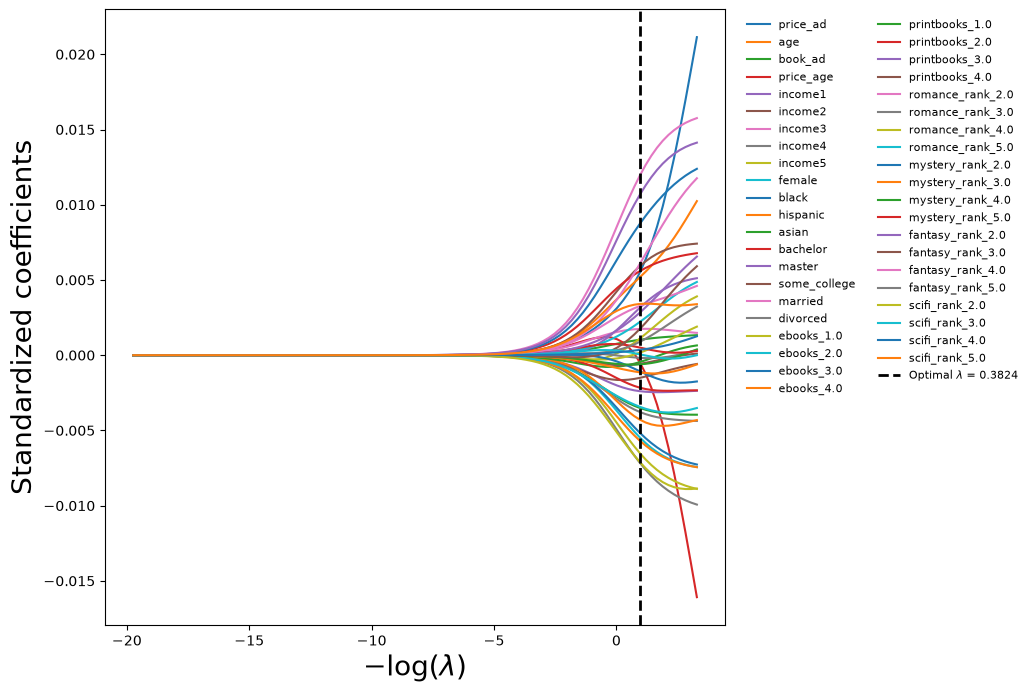

In [142]:
path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.axvline(
    -np.log(optimal_lambda_ridge),
    color='black',
    linestyle='--',
    linewidth=2,
    label=fr'Optimal $\lambda$ = {optimal_lambda_ridge:.4f}'
)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    ncol=2,
    fontsize=8,
    frameon=False
);

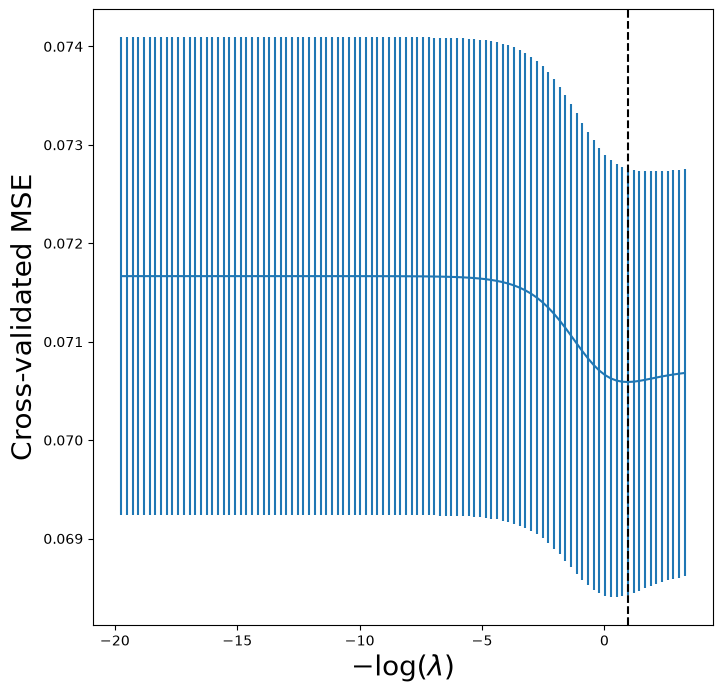

In [143]:
tuned_ridge = pipeCV.named_steps['ridge']
ridgeCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(lambdas),
            tuned_ridge.mse_path_.mean(1),
            yerr=tuned_ridge.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_ridge.alpha_), c='k', ls='--')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

In [144]:
lassoCV = skl.ElasticNetCV(n_alphas=100, l1_ratio=1, cv=kfold)
pipeCV  = Pipeline([('scaler', StandardScaler()), ('lasso', lassoCV)]).fit(X, Y)
tuned_lasso = pipeCV.named_steps['lasso']
tuned_lasso.alpha_, np.min(tuned_lasso.mse_path_.mean(1))
(tuned_lasso.coef_ == 0).sum()                       # how many variables dropped
lambdas, soln_array = skl.Lasso.path(Xs, Y, l1_ratio=1, n_alphas=100)[:2]
optimal_lambda_lasso = tuned_lasso.alpha_

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:1663: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


In [145]:
lambdas_l, soln_array_l = skl.Lasso.path(Xs,
                                    Y,
                                    l1_ratio=1,
                                    n_alphas=100)[:2]
soln_path_l = pd.DataFrame(soln_array_l.T,
                         columns=D.columns,
                         index=-np.log(lambdas_l))

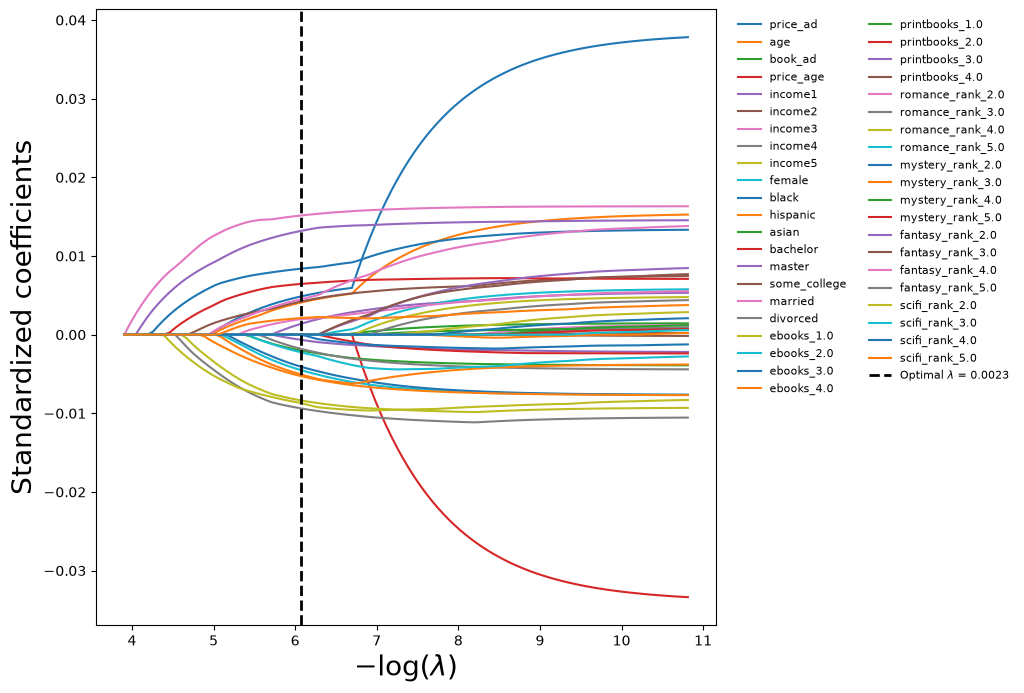

In [146]:
path_fig, ax = subplots(figsize=(8,8))
soln_path_l.plot(ax=ax, legend=False)
ax.axvline(
    -np.log(optimal_lambda_lasso),
    color='black',
    linestyle='--',
    linewidth=2,
    label=fr'Optimal $\lambda$ = {optimal_lambda_lasso:.4f}'
)
ax.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    ncol=2,
    fontsize=8,
    frameon=False
);
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20);


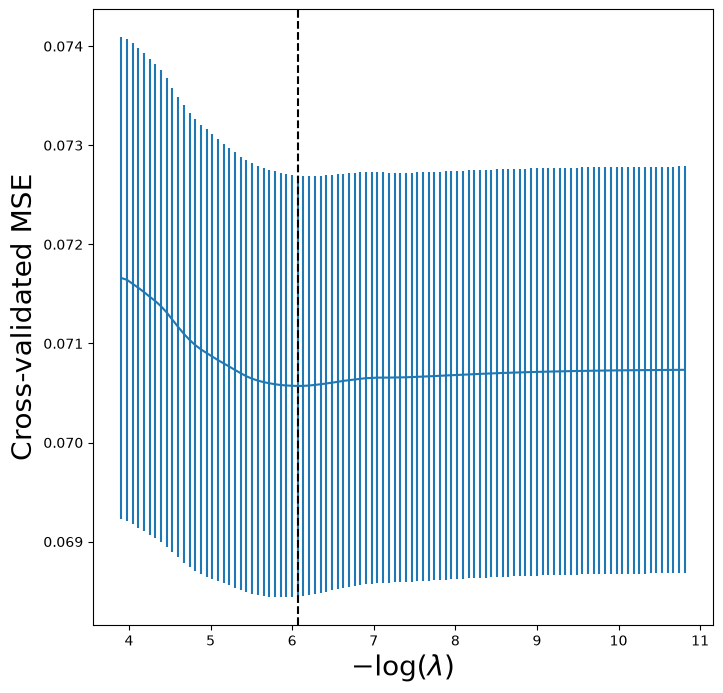

In [147]:
lassoCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(tuned_lasso.alphas_),
            tuned_lasso.mse_path_.mean(1),
            yerr=tuned_lasso.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_lasso.alpha_), c='k', ls='--')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

In [148]:
lasso_cv_mse = tuned_lasso.mse_path_.mean(axis=1).min()

print("Optimal lambda:", optimal_lambda_lasso)
print("LASSO CV MSE:", lasso_cv_mse)

Optimal lambda: 0.00231554913591638
LASSO CV MSE: 0.07057134121382468


In [149]:
print("Nonzero coefficients:", (tuned_lasso.coef_ != 0).sum())
print("Excluded predictors:", (tuned_lasso.coef_ == 0).sum())

Nonzero coefficients: 22
Excluded predictors: 20


In [150]:
selected = D.columns[tuned_lasso.coef_ != 0].tolist()
X_post_lasso = sm.add_constant(D[selected])
post_lasso = sm.OLS(Y, X_post_lasso).fit(cov_type="HC1")

print(post_lasso.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.025
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     6.477
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           2.11e-19
Time:                        01:44:05   Log-Likelihood:                -613.74
No. Observations:                6939   AIC:                             1273.
Df Residuals:                    6916   BIC:                             1431.
Df Model:                          22                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.0393      0.014  